In [7]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import itertools
from pathlib import Path
from collections import Counter

folder_P = Path("/Users/stevehalley/Code/Github/QuantumHypergraphPartitioning/data/congress-bills/numpy_20")

def get_edge_list(P):
    edges = []
    for idx in range(P.shape[1]):
        edge = tuple(np.flatnonzero(P[:, idx]))
        edges.append(edge)
    return edges

instances = {}

for idx in [7, 9]:
    filename = f"congress-bills_{idx:02d}.npy"
    P = np.load(folder_P / filename)

    edges = get_edge_list(P)
    w = np.ones(len(edges))
    n = P.shape[0]

    instances[idx] = {
        "P": P,
        "edges": edges,
        "weights": w,
        "n": n
    }

    print(f"\nInstance {idx:02d}")
    print(f"Vertices: {n}")
    print(f"Hyperedges: {len(edges)}")
    print(f"Hyperedge sizes: {[len(e) for e in edges]}")
    print(f"Hyperedges: {edges}")


Instance 07
Vertices: 18
Hyperedges: 10
Hyperedge sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Hyperedges: [(np.int64(4), np.int64(8)), (np.int64(0), np.int64(16)), (np.int64(3), np.int64(17)), (np.int64(5), np.int64(7)), (np.int64(6), np.int64(15)), (np.int64(9), np.int64(11)), (np.int64(0), np.int64(2)), (np.int64(10), np.int64(13)), (np.int64(12), np.int64(14)), (np.int64(1), np.int64(3))]

Instance 09
Vertices: 14
Hyperedges: 11
Hyperedge sizes: [2, 4, 2, 4, 2, 2, 2, 2, 2, 2, 2]
Hyperedges: [(np.int64(7), np.int64(10)), (np.int64(1), np.int64(3), np.int64(4), np.int64(12)), (np.int64(11), np.int64(13)), (np.int64(0), np.int64(3), np.int64(4), np.int64(12)), (np.int64(2), np.int64(9)), (np.int64(5), np.int64(12)), (np.int64(6), np.int64(9)), (np.int64(6), np.int64(10)), (np.int64(4), np.int64(5)), (np.int64(0), np.int64(13)), (np.int64(8), np.int64(13))]


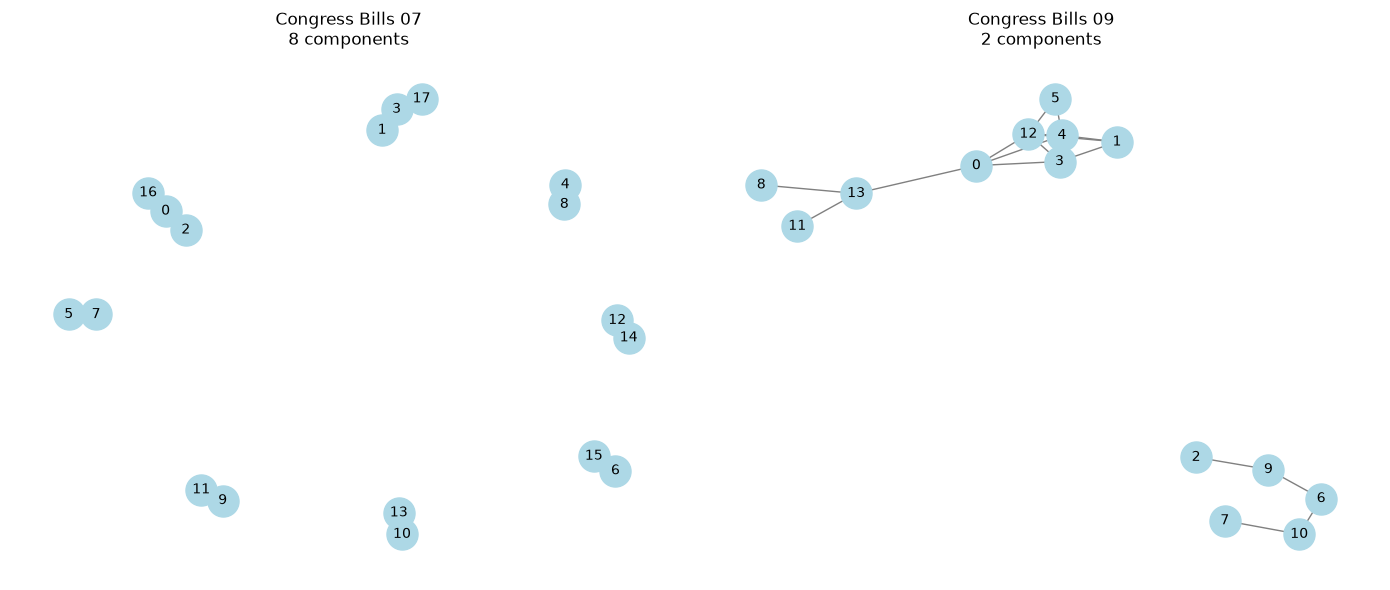

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, idx in zip(axes, [7, 9]):
    P = instances[idx]["P"]
    results, G = analyze_hypergraph(P)

    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx(
        G,
        pos,
        ax=ax,
        with_labels=True,
        node_color="lightblue",
        node_size=500,
        edge_color="gray",
        font_size=10
    )

    ax.set_title(
        f"Congress Bills {idx:02d}\n"
        f"{results['connected_components']} components"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()